# 03 — Trực quan hóa dữ liệu NUCLE

Chạy **Run All** với kernel Python của dự án (pandas, IPython và Matplotlib). Chạy `uv sync --locked` tại thư mục dự án để cài dependency. Biểu đồ được vẽ bằng Matplotlib. Mỗi annotation là một quan sát, không phải một câu độc lập. Notebook chỉ đọc dữ liệu, không xóa hoặc gộp annotation.


## Báo cáo tổng quát: dữ liệu, preparation và đối chiếu v1/v2

### 1. Phạm vi và cấu trúc dữ liệu

Nguồn NUCLE hiện có **44.912 annotation** trên **1.397 essay**. Năm nhãn mục tiêu là `ArtOrDet`, `Prep`, `Nn`, `Vform`, `SVA`. Có **15.788 annotation mục tiêu** và **29.124 annotation ngoài phạm vi nhãn mục tiêu**. Preparation giữ toàn bộ annotation ngoài phạm vi trong provenance, còn tập mẫu lỗi chỉ gồm năm nhãn mục tiêu.

| Nhãn mục tiêu | v1 | v2 |
| --- | ---: | ---: |
| ArtOrDet | 6.640 | 6.640 |
| Prep | 2.413 | 2.413 |
| Nn | 3.768 | 3.768 |
| Vform | 1.443 | 1.443 |
| SVA | 1.524 | 1.524 |
| **Tổng mẫu dựng được** | **15.788** | **15.788** |

Mỗi mẫu chứa câu nguyên văn, span lỗi theo offset ký tự Unicode `[start, end)`, nhãn gốc, hai token ngữ cảnh trái/phải khi có, cùng liên kết provenance tới annotation, essay, paragraph và sentence. Hai bộ dữ liệu giữ **96 annotation unresolved** từ review trước; không sửa nhãn/span và không loại các trường hợp này.

| Căn chỉnh span tới token | v1 | v2 |
| --- | ---: | ---: |
| Khớp trọn token | 14.445 | 14.447 |
| Cắt một phần token | 1.132 | 1.130 |
| Chạm whitespace | 211 | 211 |
| Insertion | 0 | 0 |

### 2. Quy tắc segmentation đã triển khai

Pipeline dùng spaCy 3.8.7 English tokenizer và sentencizer. Lớp sửa ranh giới chỉ đọc paragraph nguồn, không dùng label, correction hay quyết định review. Citation parenthetical có năm, `n.d.`, URL hoặc tham chiếu số gắn với câu trước; từ hoa sau citation bắt đầu câu mới, kể cả khi source dính dấu câu và từ vào cùng token, như `2009).The`. Các continuation như `n.d.) for` và `et al.) for` không bị tách tại dấu chấm abbreviation. Boundary do sentencizer đặt bên trong citation được bỏ. Với ellipsis, chỉ từ hoa độc lập tạo câu mới; trường hợp mơ hồ được giữ để review.

Paragraph được chia thành các lát cắt liên tiếp, không trim hoặc sửa ký tự; ghép lại phải bằng paragraph nguồn. Ranh giới được phép đi qua token spaCy khi punctuation và chữ dính nhau. Artifact lưu token fragment đúng theo lát cắt nguồn. Điều này xảy ra với **2 span** (annotation 1294 và 24598); chuỗi lỗi, nhãn và offset ký tự của cả hai vẫn nguyên vẹn. Quy tắc/tokenizer hiện hành được ghi trong manifest v2.

### 3. So sánh định lượng v1 và v2

Trong bảng này, “thay đổi so với v1” của cột v1 bằng 0 theo định nghĩa baseline tự so sánh. Cột v2 ghi thay đổi thực tế so với artifact v1.

| Chỉ số | v1 baseline | v2 so với v1 |
| --- | ---: | ---: |
| Mẫu mục tiêu dựng được | 15.788 | 15.788 |
| Sentence duy nhất được annotation tham chiếu | 11.262 | 11.272 |
| Input câu khác v1 | 0 | 544 / 15.788 (3,44%) |
| Input câu giống v1 | 15.788 / 15.788 | 15.244 / 15.788 (96,56%) |
| Annotation có sentence ID khác v1 | 0 | 533 / 15.788 (3,38%) |
| Metadata annotation nguồn thay đổi | 0 | 0 / 44.912 |
| Offset tuyệt đối hoặc chuỗi span thay đổi | 0 | 0 / 15.788 |
| Tokenization của span thay đổi do boundary cắt token | 0 | 2 / 15.788 |
| Trạng thái giữ/loại mẫu thay đổi | 0 | 0 |

Trong **533** annotation đổi sentence ID, **120** đồng thời có input câu đổi; **413** chỉ đổi ID vì chỉ số sentence phía trước trong paragraph dịch chuyển. Trong 544 input câu đổi, **424** giữ nguyên sentence ID và **120** đổi sentence ID. Có **30** mẫu đổi danh sách token ngữ cảnh trái/phải. Chia theo nhãn, số input đổi là: ArtOrDet 237, Nn 120, Prep 88, SVA 61, Vform 38.

Các con số “metadata nguồn/span thay đổi” không bị bỏ trống: so sánh v1-v2 xác nhận **0 thay đổi** ở essay/paragraph, offset nguồn, nhãn gốc, cờ chất lượng và review status; cả 15.788 span giữ cùng offset tuyệt đối và cùng chuỗi lỗi. Source SHA256 của hai artifact giống nhau: `8441a60060730bdc6af1e79a064c68441ecb24a66da91ea2aab0061a64a130ac`.

### 4. Review ranh giới và bằng chứng

Review v1 đã đọc **69 annotation trên 68 câu**: 54 boundary acceptable, 13 boundary issue và 2 unresolved. Trong v2, input của cả **13/13** ca boundary issue đều thay đổi theo quy tắc mới. Hai ca unresolved **31297** và **39538** không bị chỉnh hoặc loại.

Comparison report tạo packet mới **50 mẫu**: 25 mẫu fresh (5 mỗi nhãn) và 25 mẫu có input câu đổi (5 mỗi nhãn). Packet được rà soát hỗ trợ bằng AI; không thấy thêm ca mất span hoặc mất chữ đầu câu trong các mẫu đã xem. Việc này không thay thế adjudication độc lập. Hai ca unresolved và các quy tắc ellipsis vẫn cần người đánh giá khi cần kết luận ngữ nghĩa.

### 5. Công việc đã làm và artifact

- Đọc lại đặc tả preparation, trạng thái dự án và boundary review v1; giữ schema, nhãn, offset nguồn và cách ghi provenance.
- Triển khai quy tắc ranh giới v2 trong `src/data/sentence_boundaries.py`; thêm lựa chọn policy v1/v2 và tạo bộ v2 riêng trong `src/data/prepare_nucle.py`.
- Tạo `src/data/compare_preparation.py` để kiểm tra checksum, inventory 44.912 annotation, metadata, sample retention, offset span và token overlap; xuất diff, regression cases và fresh review packet.
- Dựng v2, đối chiếu cơ học đủ 15.788 mẫu; kiểm tra 50 mẫu mới; sửa các trường hợp dính citation/ngoặc và `n.d.) for` trước khi chốt artifact hiện hành.
- Thêm báo cáo Markdown này vào notebook và cập nhật trạng thái/đặc tả để trỏ đúng v2.

Artifact hiện hành: `data_set/processed/nucle_preparation_v2/` gồm `samples.jsonl`, `sentences.jsonl`, `provenance.jsonl`, `boundary_challenges.jsonl`, `summary.json`, `manifest.json` và `manifest.sha256`. Manifest digest: `9f9fc5405492d03133bab2a89759af3504028d05568829d27a6cdc47838256a0`. Schema v2 gắn `boundary_flags` và `boundary_review_status` vào sample/provenance; hai case đang unresolved được giữ trong `boundary_challenges.jsonl`.

Challenge regression cho hai case mơ hồ nằm ở `tests/test_boundary_challenges.py` và `tests/fixtures/nucle_boundary_challenges.jsonl`; chạy cùng boundary/preparation tests cho kết quả 57 passed. Comparison evidence: `reports/nucle_preparation_v2_comparison/` gồm `comparison_summary.json`, `diff.jsonl`, `regression_cases.jsonl`, `fresh_packet.jsonl` và `fresh_selection.json`. Chưa chốt duplicate/boilerplate groups, train/validation/test split hoặc benchmark; báo cáo corpus này không khẳng định chất lượng ngữ nghĩa của toàn bộ annotation.


### Preparation v2: verification run (2026-10-12)

An independent rebuild retained all 15,788 target annotations and reproduced every output SHA-256 from the current v2 dataset. Both manifests validated internally; their canonical digests differ because each manifest records its build time. The 29,124 non-target annotations are out of scope, not rejected target samples. There are 0 unconstructible target samples. Retained alignment counts are exact=14,447, partial-token=1,130, whitespace-edge=211; all three are supported alignment categories.

Boundary challenge IDs 31297 and 39538 remain in both samples and provenance with their respective ambiguity flags and unresolved status. V1/v2 comparison mechanically checked 15,788 samples, found unchanged source metadata and span offsets, and reports 544 changed sentence inputs, 533 changed sentence IDs, and 0 retention changes.

After removing the one-off review modules, the data-focused suite passes 73 tests. Full pytest collection remains blocked by tests/test_model.py and tests/test_training.py, which import the absent src.data.dataset module.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/data/parse_nucle.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the notebook from inside the project.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data.constants import SGML_FILE, TARGET_LABELS
from src.data.nucle_sgml import load_nucle
from src.data.parse_nucle import documents_to_dataframe

if not SGML_FILE.is_file():
    raise FileNotFoundError(f'Place the licensed NUCLE corpus at {SGML_FILE}')
docs = load_nucle(SGML_FILE)
if not docs:
    raise ValueError('No documents found in corpus.')
df = documents_to_dataframe(docs)
target = df.loc[df.error_type.isin(TARGET_LABELS)].copy()
display(pd.Series({
    'Total essays': len(docs),
    'Total annotations': len(df),
    'Error labels': df.error_type.nunique(),
    'Target annotations': len(target),
    'Target coverage (%)': round(100 * len(target) / len(df), 2) if len(df) else 0,
}, name='Value').to_frame())


,Value
Total essays,1397.00
Total annotations,44912.00
Error labels,28.00
Target annotations,15788.00
Target coverage (%),35.15


## Hàm vẽ biểu đồ

Thanh ngang bắt đầu từ 0. Số cuối thanh là giá trị chính xác. Màu xanh biểu thị phân bố; màu cam biểu thị cờ cần xem xét.


In [2]:
def bar_chart(values, title, unit='annotation', color='#2563eb'):
    values = pd.Series(values).fillna(0)
    if values.empty:
        print(f'{title}: no data.')
        return
    fig, ax = plt.subplots(figsize=(11, max(3, 0.35 * len(values) + 1.3)), layout='constrained')
    bars = ax.barh(range(len(values)), values.to_numpy(dtype=float), color=color)
    ax.set_yticks(range(len(values)), labels=[str(label) for label in values.index])
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f'{value:,.0f}' for value in values], padding=5)
    ax.set_xlim(0, max(float(values.max()), 1) * 1.18)
    ax.set(title=title, xlabel=f'Count ({unit})')
    ax.xaxis.grid(True, alpha=0.2)
    ax.set_axisbelow(True)
    plt.show()
    plt.close(fig)


## 1. Phân bố tất cả nhãn lỗi

Đếm toàn bộ annotation, bao gồm dòng có cờ chất lượng. Chênh lệch độ dài thanh thể hiện mất cân bằng nhãn.


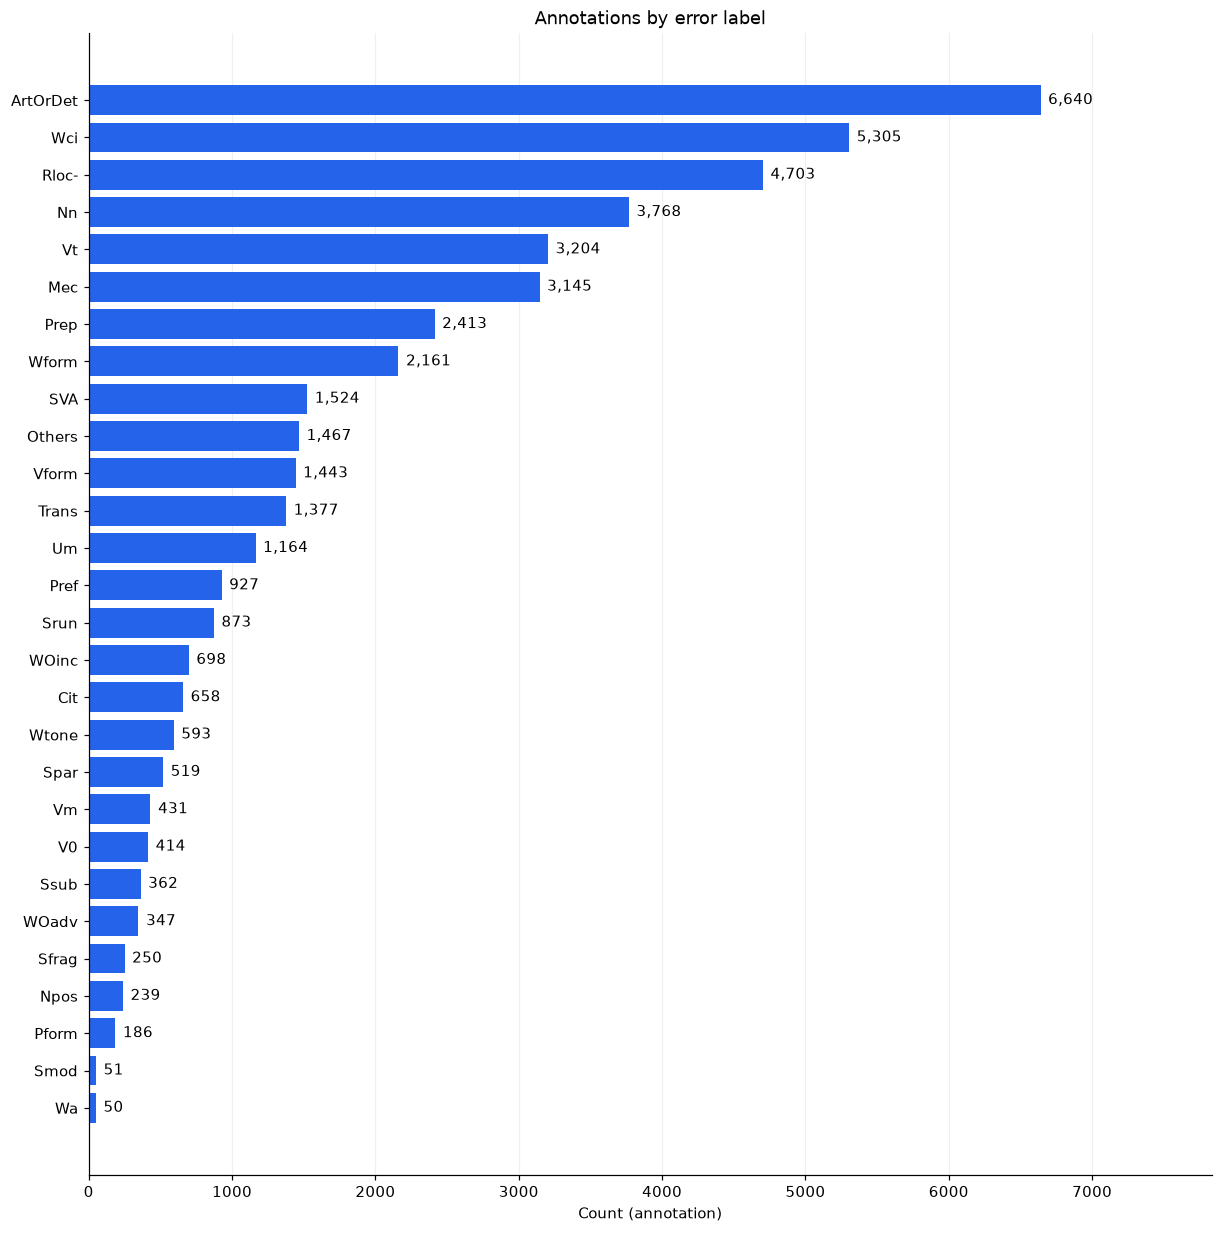

In [3]:
all_counts = df.error_type.value_counts(dropna=False)
bar_chart(all_counts, 'Annotations by error label')


## 2. Năm nhãn mục tiêu

Phần trăm nhóm mục tiêu và toàn corpus có mẫu số khác nhau. Số bài tính bằng essay_index để không gộp tài liệu trùng essay_id.


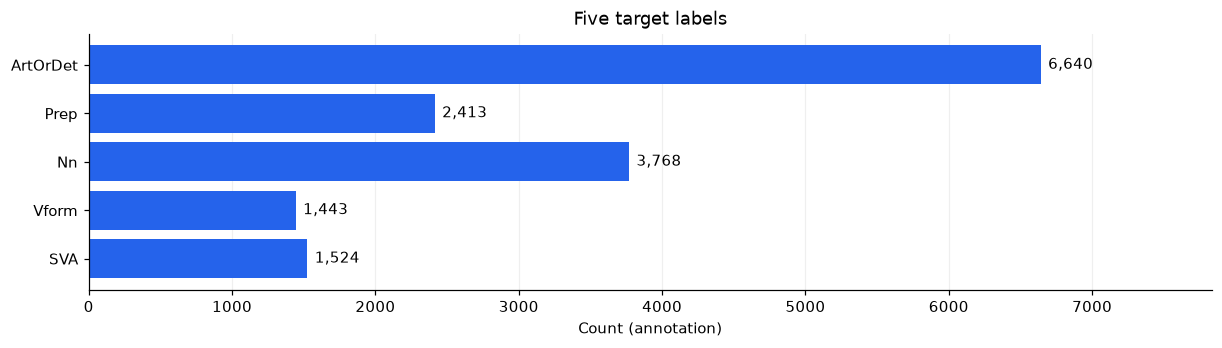

,annotation,% target subset,% corpus,Essays containing label
error_type,,,,
ArtOrDet,6640,42.06,14.78,1178
Prep,2413,15.28,5.37,954
Nn,3768,23.87,8.39,1027
Vform,1443,9.14,3.21,690
SVA,1524,9.65,3.39,746


Largest / smallest class ratio: 4.60


In [4]:
counts = target.error_type.value_counts().reindex(TARGET_LABELS, fill_value=0)
summary = counts.rename('annotation').to_frame()
summary['% target subset'] = counts / max(len(target), 1) * 100
summary['% corpus'] = counts / max(len(df), 1) * 100
summary['Essays containing label'] = target.groupby('error_type').essay_index.nunique().reindex(TARGET_LABELS, fill_value=0)
bar_chart(counts, 'Five target labels')
display(summary.round(2))
positive = counts[counts > 0]
if len(positive) == len(TARGET_LABELS):
    print(f'Largest / smallest class ratio: {positive.max() / positive.min():.2f}')
else:
    print('Some target labels are absent; five-class ratio is undefined.')


## 3. Loại chỉnh sửa theo nhãn

Bảng màu hiển thị phần trăm theo hàng; hàng không có annotation giữ bằng 0. invalid_offset, cross_paragraph và missing_correction là trạng thái dữ liệu, không phải thao tác chỉnh sửa đã xác định.


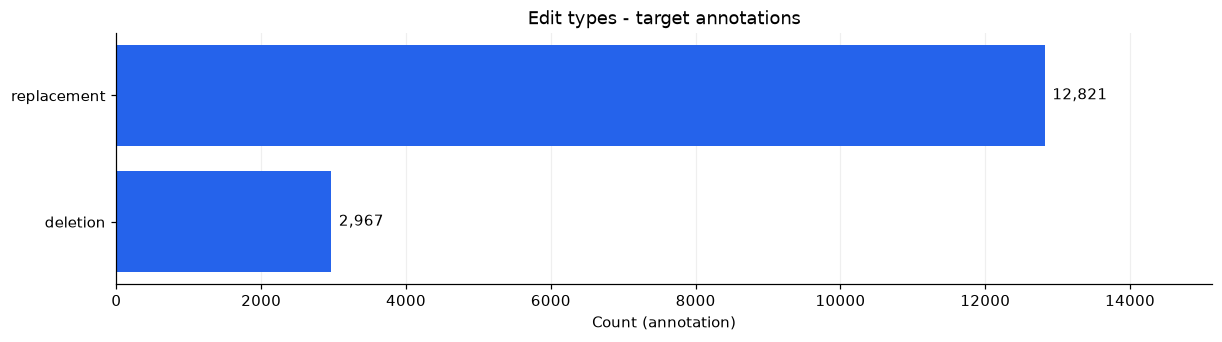

edit_type,deletion,replacement
error_type,,
ArtOrDet,1941,4699
Prep,678,1735
Nn,214,3554
Vform,51,1392
SVA,83,1441


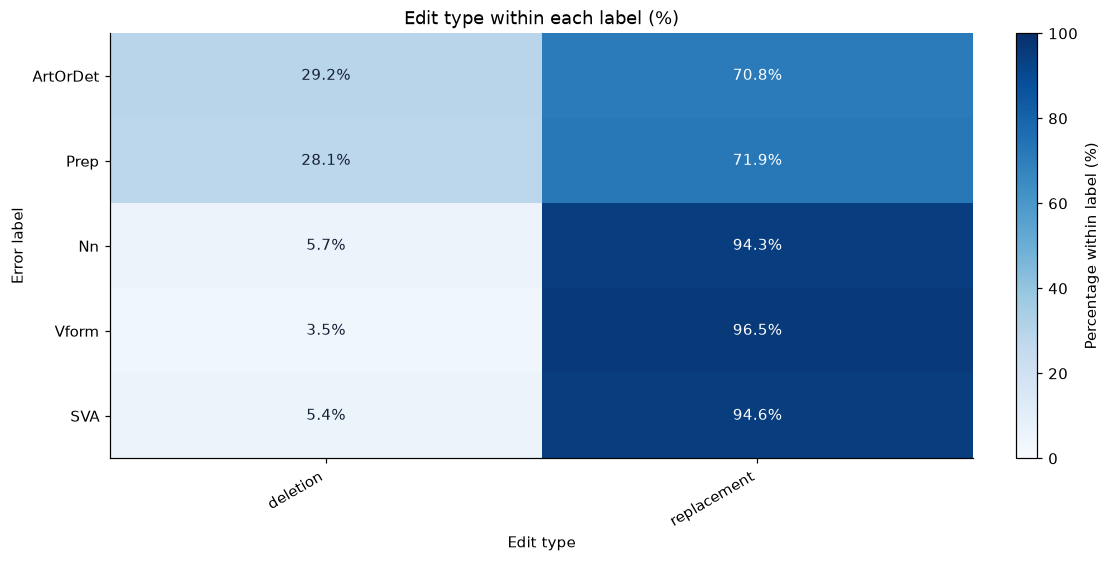

In [5]:
bar_chart(target.edit_type.value_counts(), 'Edit types - target annotations')
edit_table = pd.crosstab(target.error_type, target.edit_type).reindex(TARGET_LABELS, fill_value=0)
edit_pct = edit_table.div(edit_table.sum(axis=1).replace(0, float('nan')), axis=0).fillna(0) * 100
display(edit_table)
if edit_pct.shape[1] == 0:
    print('No target edits available for the heatmap.')
else:
    fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
    heatmap = ax.imshow(edit_pct.to_numpy(dtype=float), cmap='Blues', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(edit_pct.columns)), labels=edit_pct.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(edit_pct.index)), labels=edit_pct.index)
    for row in range(len(edit_pct.index)):
        for col in range(len(edit_pct.columns)):
            value = edit_pct.iloc[row, col]
            ax.text(col, row, f'{value:.1f}%', ha='center', va='center',
                    color='white' if value >= 60 else '#172033')
    ax.set(title='Edit type within each label (%)', xlabel='Edit type', ylabel='Error label')
    fig.colorbar(heatmap, ax=ax, label='Percentage within label (%)')
    plt.show()
    plt.close(fig)


## 4. Số annotation mục tiêu mỗi bài

Bao gồm tất cả bài trong SGML, kể cả bài có 0 lỗi mục tiêu. Các khoảng có độ rộng khác nhau: thanh biểu thị số bài, không phải mật độ xác suất.


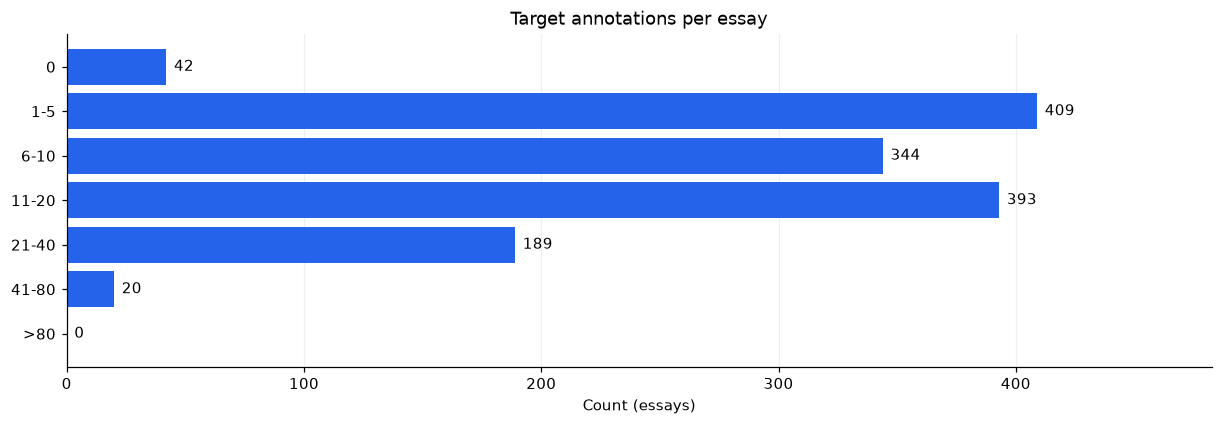

,Annotation / essays
count,1397.000000
mean,11.301360
std,9.365781
min,0.000000
25%,4.000000
50%,9.000000
75%,16.000000
95%,30.000000
max,62.000000


In [6]:
per_essay = target.groupby('essay_index').size().reindex(range(len(docs)), fill_value=0)
error_bins = [-1, 0, 5, 10, 20, 40, 80, float('inf')]
error_labels = ['0', '1-5', '6-10', '11-20', '21-40', '41-80', '>80']
grouped = pd.cut(per_essay, bins=error_bins, labels=error_labels).value_counts(sort=False)
bar_chart(grouped, 'Target annotations per essay', unit='essays')
display(per_essay.describe(percentiles=[.25, .5, .75, .95]).rename('Annotation / essays').to_frame())


## 5. Độ dài đoạn lỗi theo ký tự

Chỉ đo span có offset hợp lệ, nằm trong một đoạn và tái dựng được. Span rỗng hợp lệ dài 0, không thay span thiếu bằng chuỗi rỗng. Không cắt đuôi phân bố.


Measured: 15,788; Excluded: 0


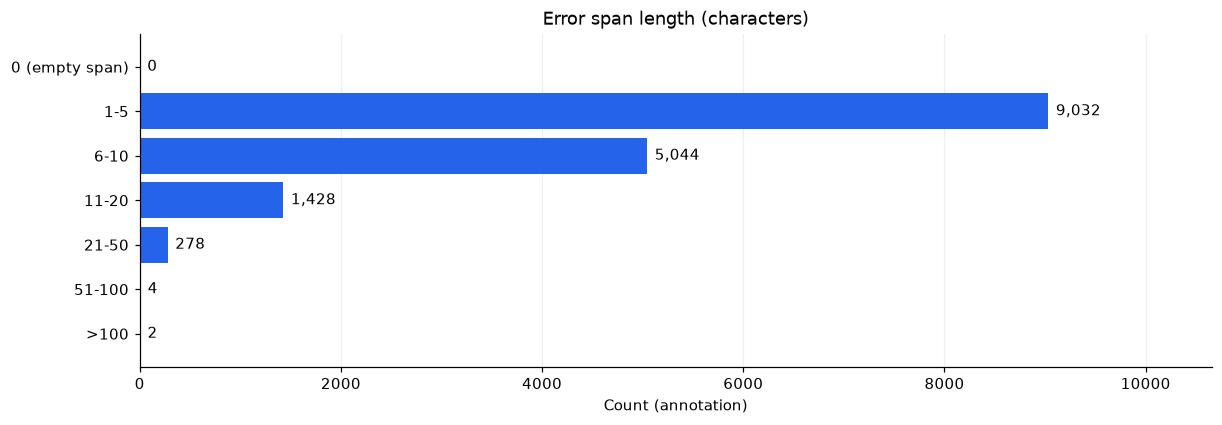

,count,mean,median,max
error_type,,,,
ArtOrDet,6640,6.26,4.0,74
Prep,2413,3.25,2.0,42
Nn,3768,6.74,7.0,57
Vform,1443,7.09,7.0,156
SVA,1524,4.91,4.0,151


In [7]:
valid_spans = target.loc[target.valid_offset & ~target.cross_paragraph & target.error_span.notna()].copy()
valid_spans['span_length'] = valid_spans.error_span.str.len()
print(f'Measured: {len(valid_spans):,}; Excluded: {len(target) - len(valid_spans):,}')
length_bins = [-1, 0, 5, 10, 20, 50, 100, float('inf')]
length_labels = ['0 (empty span)', '1-5', '6-10', '11-20', '21-50', '51-100', '>100']
length_counts = pd.cut(valid_spans.span_length, bins=length_bins, labels=length_labels).value_counts(sort=False)
bar_chart(length_counts, 'Error span length (characters)')
display(valid_spans.groupby('error_type').span_length.agg(['count', 'mean', 'median', 'max']).reindex(TARGET_LABELS).round(2))


## 6. Các cờ chất lượng trên toàn corpus

Một annotation có thể mang nhiều cờ, nên các nhóm không loại trừ nhau. Correction rỗng có thể là thao tác xóa hợp lệ, khác với thiếu thẻ correction. Cờ kỹ thuật không khẳng định lỗi ngữ nghĩa. Xem notebook 02_nucle_data_quality.ipynb để phân tích overlap và nghi trùng.


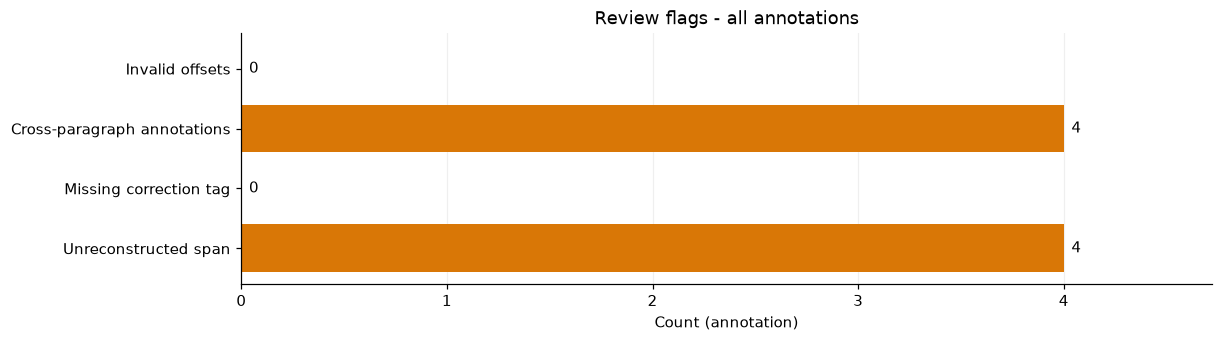

,Annotations,% corpus
Invalid offsets,0,0.00
Cross-paragraph annotations,4,0.01
Missing correction tag,0,0.00
Unreconstructed span,4,0.01


In [8]:
flags = pd.Series({
    'Invalid offsets': int((~df.valid_offset).sum()),
    'Cross-paragraph annotations': int(df.cross_paragraph.sum()),
    'Missing correction tag': int(df.missing_correction.sum()),
    'Unreconstructed span': int(df.error_span.isna().sum()),
})
bar_chart(flags, 'Review flags - all annotations', color='#d97706')
display(pd.DataFrame({'Annotations': flags, '% corpus': flags / max(len(df), 1) * 100}).round(2))


## Gợi ý diễn giải

- Dùng phân bố nhãn để đánh giá mất cân bằng, không suy ra hiệu quả mô hình.
- So sánh số bài chứa nhãn với số annotation để xem mức tập trung lỗi.
- Kiểm tra span dài và cờ chất lượng trước khi quyết định tiền xử lý.
- Notebook không chia tập dữ liệu và không tự loại annotation.
